# Etapa 7b — Medidas clínicas: expertos contra algoritmo

Las medidas y sus parámetros quedaron fijados en `07a` solo con los expertos. Acá se calculan, con los mismos parámetros, sobre las máscaras de desarrollo con validación cruzada (`05d`: cada imagen segmentada con los pesos y el umbral de la vuelta en la que quedó afuera), en cuatro versiones: la **combinación** (algoritmo final) y la **referencia** (detector de líneas solo), cada una con **fracción fija** y con **valor fijo** (desvío 14.7).

**Qué se mide** (esquema, etapa 7):
1. **Concordancia** con los expertos, por medida: correlación intraclase de acuerdo absoluto y Bland–Altman (sesgo y límites de acuerdo, algoritmo menos experto), con intervalos al 95 % remuestreando personas.
2. **Diferencia entre sanos y retinopatía** con cada máscara. Si la del algoritmo es distinta de la de los expertos (el intervalo de la diferencia entre las dos no incluye el cero), el algoritmo borra o agranda la diferencia y se informa como un sesgo suyo. Se repite dentro de cada nivel de compresión, solo descriptivo (hay pocas imágenes por celda).

**Qué se usa para la etapa 8** (desvío 14.7, fijado antes de calcular): la correlación intraclase media en las tres medidas, de la combinación con fracción fija y con valor fijo. Si difieren en 0,05 o más, la de mayor media es la que gana el punto 2 del desvío; si no, queda la fracción fija. La decisión final es de la etapa 8, después de la robustez.


In [1]:
import sys
import time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as C
from src.data import dev_ids, load_split
from src.evaluation import map_images
from src.stats import (bland_altman, icc_absolute, percentile_interval, person_bootstrap_means,
                       person_bootstrap_stat)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 20)
ids = dev_ids()
dev = load_split().set_index("image").loc[ids]
SOURCES = ["combinación", "combinación valor fijo", "referencia", "referencia valor fijo"]
MEAS = ["proporción", "longitud", "tortuosidad"]
print(f"Poda {C.CLINICAL_SPUR_REL * C.FOV_DIAMETER_REF:.0f} píxeles, largo mínimo {C.CLINICAL_MIN_SEGMENT_REL * C.FOV_DIAMETER_REF:.0f} píxeles (de 07a)")

Poda 5 píxeles, largo mínimo 25 píxeles (de 07a)


In [2]:
def measure(image_id):
    from src.clinical import clinical_measures
    from src.data import load_fov, load_vessels
    from src.pipeline import load_dev_mask
    fov = load_fov(image_id)
    masks = {"experto": load_vessels(image_id), **{s: load_dev_mask(image_id, s) for s in SOURCES}}
    return [{"image": image_id, "fuente": s, **clinical_measures(m, fov)} for s, m in masks.items()]

t = time.time()
M = pd.DataFrame([r for rows in map_images(measure, ids, workers=4) for r in rows])
M.to_csv(ROOT / "results" / "07b_medidas.csv", index=False)
print(f"{time.time() - t:.0f} s")
frame = pd.concat({m: M.pivot(index="image", columns="fuente", values=m) for m in MEAS}, axis=1).loc[ids]
print("Media por fuente:")
M.groupby("fuente")[MEAS + ["tramos"]].mean().loc[["experto"] + SOURCES].round(4)

396 s
Media por fuente:


,proporción,longitud,tortuosidad,tramos
fuente,,,,
experto,0.0919,24.1853,1.0182,559.2667
combinación,0.0939,21.9802,1.0140,590.5333
combinación valor fijo,0.0875,20.6206,1.0137,531.2000
referencia,0.0892,17.6092,1.0133,386.6667
referencia valor fijo,0.0900,17.7404,1.0132,389.9333


## 1. Concordancia con los expertos

In [3]:
def iccs(f):
    return np.array([icc_absolute(f[(m, "experto")], f[(m, s)]) for s in SOURCES for m in MEAS])

boot = person_bootstrap_stat(frame, dev["person"], iccs)
lo, hi = percentile_interval(boot)
rows = []
for j, (s, m) in enumerate([(s, m) for s in SOURCES for m in MEAS]):
    ba = bland_altman(frame[(m, "experto")], frame[(m, s)])
    rows.append({"fuente": s, "medida": m, "correlación intraclase": iccs(frame)[j], "inferior": lo[j],
                 "superior": hi[j], "Pearson": frame[(m, "experto")].corr(frame[(m, s)]), **ba})
conc = pd.DataFrame(rows).set_index(["fuente", "medida"])
conc.round(4)

correlación intraclase  inferior  superior  Pearson   sesgo  límite inferior  límite superior
fuente                 medida                                                                                                    
combinación            proporción                  -0.1329   -0.4090    0.1150  -0.2323  0.0020          -0.0337           0.0376
                       longitud                    -0.0384   -0.3398    0.3072  -0.0592 -2.2051          -8.5866           4.1764
                       tortuosidad                  0.1059   -0.0327    0.3021   0.3275 -0.0041          -0.0090           0.0008
combinación valor fijo proporción                   0.3336    0.1436    0.5321   0.5007 -0.0044          -0.0324           0.0235
                       longitud                     0.1809    0.0475    0.3390   0.4229 -3.5647          -8.4191           1.2897
                       tortuosidad                  0.1043    0.0036    0.2479   0.3916 -0.0044          -0.0090           0.0002
referencia             proporción                   0.0013   -0.0092    0.0122   0.0548 -0.0027          -0.0348           0.0294
                       longitud                     0.0072   -0.0375    0.0485   0.0681 -6.5760         -11.9258          -1.2263
                       tortuosidad                  0.1193    0.0318    0.2282   0.4475 -0.0049          -0.0094          -0.0004
referencia valor fijo  proporción                   0.2740    0.0245    0.5101   0.3502 -0.0019          -0.0322           0.0284
                       longitud                     0.0556   -0.0111    0.1214   0.2772 -6.4449         -11.9476          -0.9421
                       tortuosidad                  0.1349    0.0312    0.2576   0.5004 -0.0049          -0.0093          -0.0006

In [4]:
mean_icc = boot.reshape(len(boot), len(SOURCES), len(MEAS)).mean(axis=2)
point = iccs(frame).reshape(len(SOURCES), len(MEAS)).mean(axis=1)
lo_m, hi_m = percentile_interval(mean_icc)
print("Correlación intraclase media en las tres medidas:")
print(pd.DataFrame({"media": point, "inferior": lo_m, "superior": hi_m}, index=SOURCES).round(4).to_string())
d = mean_icc[:, 1] - mean_icc[:, 0]
dlo, dhi = percentile_interval(d)
print(f"\nCombinación, valor fijo menos fracción fija: {point[1] - point[0]:+.4f} (intervalo {dlo:+.4f} a {dhi:+.4f})")
for a, b, label in ((0, 2, "fracción fija"), (1, 3, "valor fijo")):
    dlo, dhi = percentile_interval(mean_icc[:, a] - mean_icc[:, b])
    print(f"Con {label}, combinación menos referencia: {point[a] - point[b]:+.4f} (intervalo {dlo:+.4f} a {dhi:+.4f})")

Correlación intraclase media en las tres medidas:
                         media  inferior  superior
combinación            -0.0218   -0.1760    0.1432
combinación valor fijo  0.2063    0.1025    0.3226
referencia              0.0426    0.0086    0.0812
referencia valor fijo   0.1548    0.0374    0.2600

Combinación, valor fijo menos fracción fija: +0.2281 (intervalo +0.0837 a +0.3741)
Con fracción fija, combinación menos referencia: -0.0644 (intervalo -0.1959 a +0.0825)
Con valor fijo, combinación menos referencia: +0.0514 (intervalo -0.0044 a +0.1276)


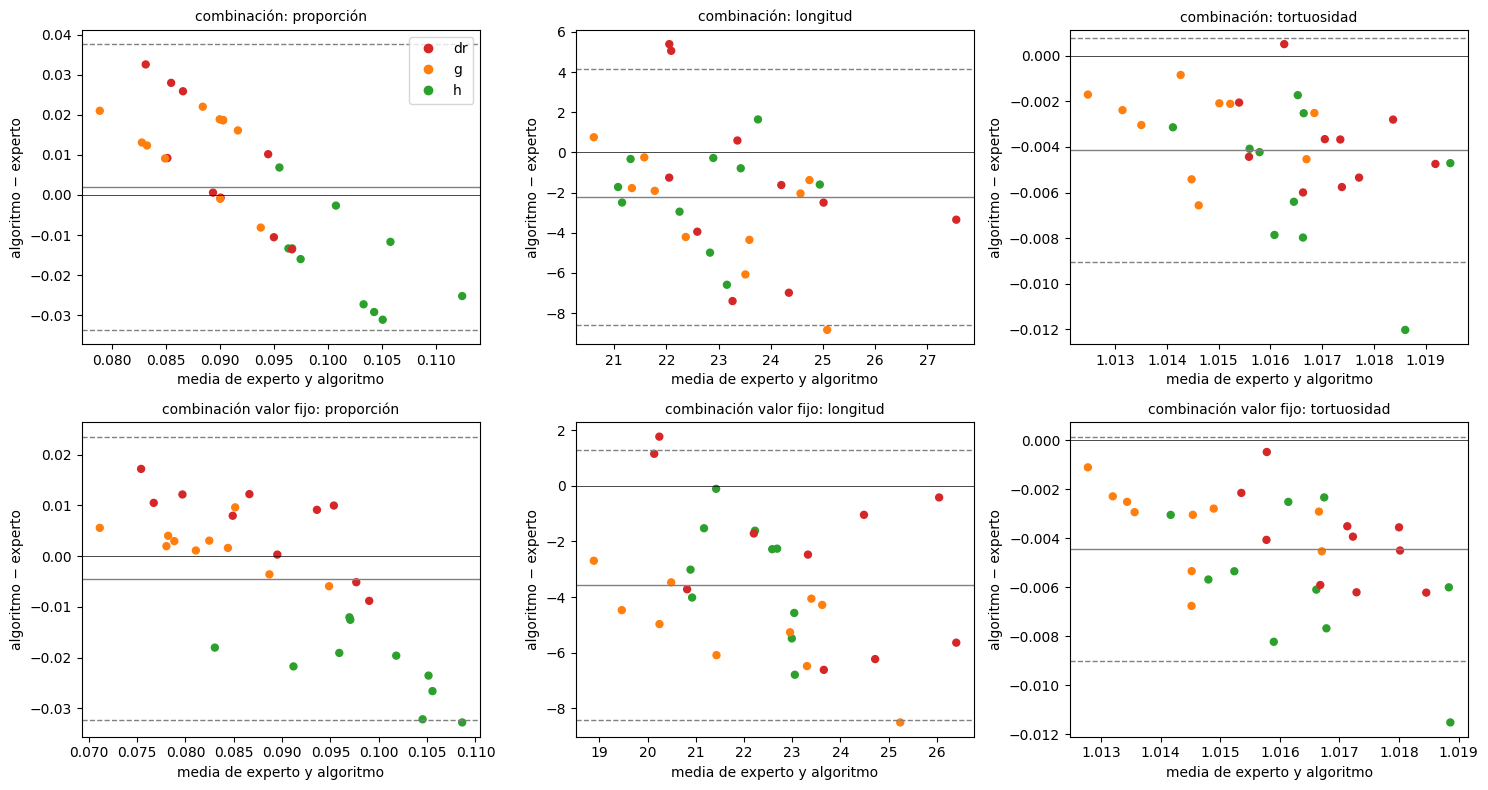

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
colors = {"dr": "tab:red", "g": "tab:orange", "h": "tab:green"}
for r, s in enumerate(["combinación", "combinación valor fijo"]):
    for c, m in enumerate(MEAS):
        ax = axes[r, c]
        x, y = frame[(m, "experto")], frame[(m, s)]
        ba = bland_altman(x, y)
        ax.scatter((x + y) / 2, y - x, c=[colors[g] for g in dev["group"]], s=25)
        for k, ls in (("sesgo", "-"), ("límite inferior", "--"), ("límite superior", "--")):
            ax.axhline(ba[k], color="gray", ls=ls, lw=1)
        ax.axhline(0, color="black", lw=0.5)
        ax.set_title(f"{s}: {m}", fontsize=10)
        ax.set_xlabel("media de experto y algoritmo"); ax.set_ylabel("algoritmo − experto")
axes[0, 0].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=v, label=k) for k, v in colors.items()])
plt.tight_layout(); plt.show()

## 2. Diferencia entre sanos y retinopatía

In [6]:
h = frame[dev["group"] == "h"]
dr = frame[dev["group"] == "dr"]
bh = person_bootstrap_means(h, dev["person"], seed=C.SEED)
bd = person_bootstrap_means(dr, dev["person"], seed=C.SEED + 1)
diff_point = (h.mean() - dr.mean())
diff_boot = pd.DataFrame(bh - bd, columns=frame.columns)
rows = []
for m in MEAS:
    for s in ["experto"] + SOURCES:
        lo_, hi_ = percentile_interval(diff_boot[(m, s)].to_numpy())
        row = {"medida": m, "fuente": s, "sanos − retinopatía": diff_point[(m, s)], "inferior": lo_, "superior": hi_}
        if s != "experto":
            dd = (diff_boot[(m, s)] - diff_boot[(m, "experto")]).to_numpy()
            row["contra el experto"] = diff_point[(m, s)] - diff_point[(m, "experto")]
            row["c. inferior"], row["c. superior"] = percentile_interval(dd)
        rows.append(row)
pd.DataFrame(rows).set_index(["medida", "fuente"]).round(4)

sanos − retinopatía  inferior  superior  contra el experto  c. inferior  c. superior
medida      fuente                                                                                                      
proporción  experto                              0.0253    0.0151    0.0360                NaN          NaN          NaN
            combinación                         -0.0010   -0.0066    0.0047            -0.0263      -0.0402      -0.0127
            combinación valor fijo              -0.0030   -0.0094    0.0026            -0.0284      -0.0351      -0.0210
            referencia                          -0.0000   -0.0003    0.0002            -0.0254      -0.0360      -0.0153
            referencia valor fijo               -0.0051   -0.0124    0.0010            -0.0305      -0.0391      -0.0218
longitud    experto                             -0.7693   -2.7746    1.5964                NaN          NaN          NaN
            combinación                         -1.1773   -3.0707    0.7804            -0.4080      -3.9065       2.7191
            combinación valor fijo              -1.4429   -2.8216   -0.4112            -0.6736      -3.1247       1.7047
            referencia                          -0.8321   -1.8000    0.0117            -0.0629      -2.8791       2.3587
            referencia valor fijo               -1.8547   -3.4971   -0.6046            -1.0854      -4.0636       1.6189
tortuosidad experto                              0.0003   -0.0016    0.0023                NaN          NaN          NaN
            combinación                         -0.0013   -0.0026   -0.0000            -0.0017      -0.0044       0.0006
            combinación valor fijo              -0.0015   -0.0025   -0.0002            -0.0018      -0.0042       0.0004
            referencia                          -0.0011   -0.0022   -0.0000            -0.0015      -0.0039       0.0007
            referencia valor fijo               -0.0012   -0.0024    0.0003            -0.0015      -0.0038       0.0006

In [7]:
print("Media por nivel de compresión y grupo (descriptivo; cantidad de imágenes en la primera columna):")
L = M.join(dev[["group", "more_compressed"]], on="image")
L.pivot_table(index=["more_compressed", "group"], columns="fuente", values="tortuosidad").loc[:, ["experto"] + SOURCES].round(4)

Media por nivel de compresión y grupo (descriptivo; cantidad de imágenes en la primera columna):


fuente                 experto  combinación  combinación valor fijo  referencia  referencia valor fijo
more_compressed group                                                                                 
False           dr      1.0190       1.0152                  1.0149      1.0146                 1.0146
                g       1.0150       1.0129                  1.0125      1.0119                 1.0118
                h       1.0190       1.0133                  1.0128      1.0133                 1.0130
True            dr      1.0188       1.0152                  1.0150      1.0144                 1.0144
                g       1.0180       1.0133                  1.0132      1.0116                 1.0117
                h       1.0196       1.0142                  1.0140      1.0135                 1.0136

In [8]:
print(L.groupby(["more_compressed", "group"])["image"].nunique().to_string())
for m in ("proporción", "longitud"):
    print(f"\n{m}:")
    print(L.pivot_table(index=["more_compressed", "group"], columns="fuente", values=m).loc[:, ["experto"] + SOURCES].round(4).to_string())

more_compressed  group
False            dr       8
                 g        6
                 h        4
True             dr       2
                 g        4
                 h        6

proporción:
fuente                 experto  combinación  combinación valor fijo  referencia  referencia valor fijo
more_compressed group                                                                                 
False           dr      0.0854       0.0934                  0.0920      0.0893                 0.0970
                g       0.0767       0.0928                  0.0812      0.0891                 0.0815
                h       0.1185       0.0947                  0.0915      0.0893                 0.0917
True            dr      0.0815       0.0995                  0.0877      0.0891                 0.0870
                g       0.0881       0.0946                  0.0864      0.0892                 0.0905
                h       0.1041       0.0928                  0.0858      0.

## Lectura (escrita después de correr; máscaras con el entrenamiento equilibrado de `05f`)

**Concordancia con los expertos: sigue baja** (correlación intraclase de 0,33 como máximo por medida).
- **Con fracción fija**, la combinación no concuerda (media −0,02): la proporción la fija el umbral.
- **Con valor fijo**, media 0,21: +0,23 contra la fracción (intervalo +0,08 a +0,37). La correlación de Pearson con los expertos es de 0,39 a 0,50: el algoritmo ordena las imágenes de forma parecida, pero con un corrimiento.
- **Efecto del entrenamiento equilibrado:** el corrimiento en longitud se achicó. El algoritmo mide 9 % menos esqueleto que los expertos con fracción fija y 15 % menos con valor fijo (sesgo −2,2 y −3,6 sobre 24,2 diámetros), contra 17 % y 22 % con el entrenamiento anterior. La concordancia en longitud con valor fijo sube de 0,11 a 0,18; la de tortuosidad baja de 0,17 a 0,10 (con intervalos superpuestos). La tortuosidad sigue saliendo un poco más baja que la de los expertos (−0,004).
- **Combinación contra referencia:** con valor fijo, +0,05 (intervalo −0,004 a +0,13); con fracción fija, −0,06 (intervalo −0,20 a +0,08). Ninguna diferencia es firme.
- **Para la etapa 8** (desvío 14.7, punto 2): la combinación con valor fijo supera a la de fracción fija en 0,23, más que el 0,05 fijado, así que **el valor fijo gana en concordancia clínica**. La regla se decide en la etapa 8, después de mirar la robustez (punto 1).

**Sanos contra retinopatía.**
- Con los expertos, los sanos tienen más proporción de vasos (+0,025, intervalo +0,015 a +0,036), pero no más longitud (−0,8, intervalo −2,8 a +1,6) ni más tortuosidad (+0,0003). Como la longitud no depende del ancho, la diferencia en proporción viene del ancho con que se marcaron los sanos (etapa 1c).
- Las cuatro versiones del algoritmo borran esa diferencia de proporción (contra el experto, de −0,025 a −0,031, con intervalos que no incluyen el cero). Según el esquema se informa como un sesgo del algoritmo, con la aclaración de que lo que no reproduce es, probablemente, la forma de marcar y no la retina.
- En longitud y tortuosidad el algoritmo no se distingue de los expertos (los intervalos de la diferencia incluyen el cero), y los expertos tampoco separan los grupos.
- **Por compresión:** con 2 a 8 imágenes por celda no se puede concluir nada; la tabla se informa como descriptiva.
